# Burgers: presupuesto extendido y barrido de componentes PCA

Esta corrida compara una PINN base con PCA al 99 % de varianza y PCA con `k=4, 8, 16`, usando 10 semillas y hasta 5000 pasos. El objetivo es observar cómo cambia el compromiso entre error de solución, residuo físico y tiempo cuando aumenta el presupuesto de entrenamiento o el número de modos.


## Protocolo

- Las semillas, particiones temporales, minibatches, ubicaciones de colocación y observaciones de condición inicial se comparten entre métodos dentro de cada semilla.
- El PCA se ajusta con los tiempos de entrenamiento únicamente. Se calcula una base completa por semilla y se evalúan prefijos de `k` componentes.
- Las anchuras de las MLP se ajustan para mantener sus cantidades de parámetros dentro de 5 % de la PINN base.
- Todas las variantes usan autodiferenciación de JAX para el residuo PDE durante el entrenamiento.
- La validación se revisa durante el entrenamiento y en los pasos 1000, 2500 y 5000. La prueba se evalúa solo en el checkpoint final.
- El tiempo de compilación se excluye del tiempo de pipeline; PCA incluye el tiempo de ajuste de la base.


In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
RUN_DIR = ROOT / "results" / "burgers" / "base_vs_pca" / "longer_budget_k_sweep_10_seeds_v1"
CONFIG = json.loads((RUN_DIR / "config.json").read_text(encoding="utf-8"))
RESULT = json.loads((RUN_DIR / "summary.json").read_text(encoding="utf-8"))
CHECKPOINTS = pd.read_csv(RUN_DIR / "checkpoint_metrics.csv")
TRAJECTORIES = pd.read_csv(RUN_DIR / "training_trajectories.csv")
print(f"JAX {RESULT['runtime']['jax']} | {RESULT['runtime']['device']}")
print(f"{len(CONFIG['seeds'])} semillas | {CONFIG['steps']} pasos | checkpoints {CONFIG['checkpoint_steps']}")


JAX 0.12.0.1 | cpu:0
10 semillas | 5000 pasos | checkpoints [1000, 2500, 5000]


## Validación en los checkpoints


In [2]:
rows = []
for model, checkpoints in RESULT["checkpoint_summary"].items():
    for step, stats in checkpoints.items():
        rows.append({
            "Modelo": model, "Paso": int(step), "Semillas": stats["seed_count"],
            "RMSE validación": f"{stats['validation_rmse']['mean']:.4f} ± {stats['validation_rmse']['std']:.4f}",
            "Residuo RMS validación": f"{stats['validation_pde_residual_rms']['mean']:.4f} ± {stats['validation_pde_residual_rms']['std']:.4f}",
            "Tiempo pipeline": f"{stats['elapsed_pipeline_seconds']['mean']:.2f} ± {stats['elapsed_pipeline_seconds']['std']:.2f} s",
        })
display(pd.DataFrame(rows).sort_values(["Paso", "Modelo"]))


Modelo,Paso,Semillas,RMSE validación,Residuo RMS validación,Tiempo pipeline
PINN base,1000,10,0.2485 ± 0.0213,0.2437 ± 0.0211,2.71 ± 0.55 s
PINN base,2500,10,0.1561 ± 0.0356,0.4854 ± 0.2066,6.96 ± 1.73 s
PINN base,5000,10,0.1297 ± 0.0401,0.7283 ± 0.2078,13.66 ± 2.95 s
PCA 99%,1000,10,0.1889 ± 0.0179,0.3305 ± 0.0311,1.64 ± 0.34 s
PCA 99%,2500,10,0.1786 ± 0.0197,0.3117 ± 0.0205,4.11 ± 0.85 s
PCA 99%,5000,10,0.1708 ± 0.0180,0.3064 ± 0.0191,8.14 ± 1.72 s
PCA k=4,1000,10,0.1766 ± 0.0155,0.3188 ± 0.0277,1.54 ± 0.22 s
PCA k=4,2500,10,0.1792 ± 0.0169,0.3054 ± 0.0257,4.06 ± 0.81 s
PCA k=4,5000,10,0.1685 ± 0.0194,0.2989 ± 0.0179,8.17 ± 1.92 s
PCA k=8,1000,10,0.2072 ± 0.0204,0.2696 ± 0.0412,1.57 ± 0.20 s


## Evaluación final en el conjunto de prueba (5000 pasos)


In [3]:
rows = []
for model, stats in RESULT["final_test_summary"].items():
    final_step = str(max(map(int, RESULT["checkpoint_summary"][model].keys())))
    detail = RESULT["checkpoint_summary"][model][final_step]
    rows.append({
        "Modelo": model,
        "k medio": None if detail["k"] is None else detail["k"]["mean"],
        "Varianza PCA": None if detail["retained_variance"] is None else detail["retained_variance"]["mean"],
        "RMSE prueba": f"{stats['test_rmse']['mean']:.4f} ± {stats['test_rmse']['std']:.4f}",
        "Error relativo L2": f"{stats['test_relative_l2']['mean']:.4f} ± {stats['test_relative_l2']['std']:.4f}",
        "Residuo Burgers RMS": f"{stats['test_pde_residual_rms']['mean']:.4f} ± {stats['test_pde_residual_rms']['std']:.4f}",
        "Tiempo pipeline": f"{stats['pipeline_seconds']['mean']:.2f} ± {stats['pipeline_seconds']['std']:.2f} s",
    })
display(pd.DataFrame(rows))


Modelo,k,Varianza retenida,RMSE prueba,Error relativo L2 prueba,Residuo Burgers RMS prueba,Tiempo pipeline
PINN base,—,—,0.1288 ± 0.0437,0.2088 ± 0.0644,0.7295 ± 0.2090,13.66 ± 2.95 s
PCA 99%,3.0,99.755%,0.1671 ± 0.0108,0.2725 ± 0.0141,0.3166 ± 0.0186,8.14 ± 1.72 s
PCA k=4,4.0,99.969%,0.1648 ± 0.0167,0.2684 ± 0.0220,0.3156 ± 0.0182,8.17 ± 1.92 s
PCA k=8,8.0,100.000%,0.2051 ± 0.0112,0.3343 ± 0.0096,0.2604 ± 0.0157,7.73 ± 1.02 s
PCA k=16,16.0,100.000%,0.2045 ± 0.0130,0.3333 ± 0.0132,0.2641 ± 0.0225,8.03 ± 0.75 s


## Diferencias pareadas frente a la PINN base

Valores negativos favorecen PCA en las métricas de error, residuo y tiempo.


In [4]:
rows = []
for model, metrics in RESULT["paired_final_test_differences"].items():
    for key, label in [("test_relative_l2", "Error relativo L2"),
                       ("test_pde_residual_rms", "Residuo RMS Burgers"),
                       ("elapsed_pipeline_seconds", "Tiempo pipeline")]:
        value = metrics[key]
        rows.append({"PCA": model, "Métrica": label,
                     "Diferencia media PCA − base": value["PCA_minus_base_mean"],
                     "Semillas con diferencia menor": f"{value['PCA_better_count']}/{value['n']}"})
display(pd.DataFrame(rows))


PCA,Métrica,Diferencia media PCA − base,Semillas con diferencia menor
PCA 99%,Error relativo L2,0.0636,1/10
PCA 99%,Residuo RMS Burgers,-0.4129,9/10
PCA 99%,Tiempo pipeline,-5.5151,10/10
PCA k=4,Error relativo L2,0.0596,1/10
PCA k=4,Residuo RMS Burgers,-0.4139,9/10
PCA k=4,Tiempo pipeline,-5.4855,10/10
PCA k=8,Error relativo L2,0.1255,1/10
PCA k=8,Residuo RMS Burgers,-0.4691,10/10
PCA k=8,Tiempo pipeline,-5.9331,10/10
PCA k=16,Error relativo L2,0.1245,1/10


## Tiempo hasta objetivos de validación

Se reporta el primer cruce observado en evaluaciones cada 100 pasos; el modelo puede volver a superar el umbral en checkpoints posteriores.


In [5]:
rows = []
for model, thresholds in RESULT["time_to_validation_thresholds"].items():
    for target, stats in thresholds.items():
        rows.append({
            "Modelo": model, "Objetivo": f"RMSE ≤ {target}",
            "Semillas que lo alcanzaron": f"{stats['hit_count']}/{stats['seed_count']}",
            "Tiempo medio entre las que llegaron": stats["seconds_mean_if_hit"],
        })
display(pd.DataFrame(rows))


Modelo,Objetivo,Semillas que lo alcanzaron,Tiempo medio entre las que llegaron
PINN base,RMSE ≤ 0.3,10/10,1.13 s
PINN base,RMSE ≤ 0.25,10/10,2.84 s
PINN base,RMSE ≤ 0.2,10/10,4.83 s
PCA 99%,RMSE ≤ 0.3,10/10,0.17 s
PCA 99%,RMSE ≤ 0.25,10/10,0.17 s
PCA 99%,RMSE ≤ 0.2,10/10,1.23 s
PCA k=4,RMSE ≤ 0.3,10/10,0.17 s
PCA k=4,RMSE ≤ 0.25,10/10,0.17 s
PCA k=4,RMSE ≤ 0.2,10/10,0.32 s
PCA k=8,RMSE ≤ 0.3,10/10,0.17 s


## Curvas de entrenamiento


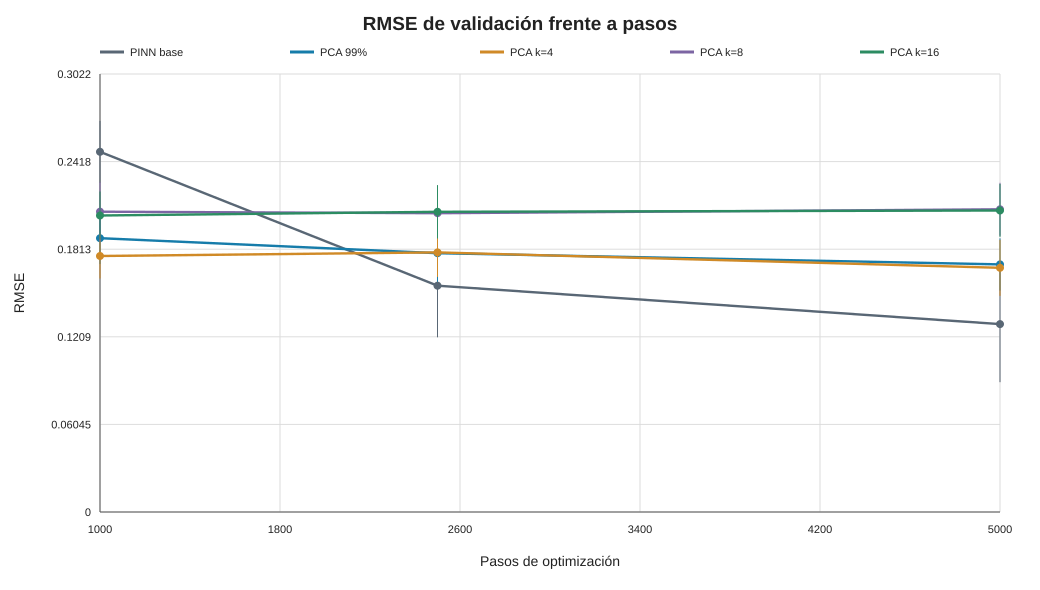

In [6]:
display(SVG(filename=str(RUN_DIR / "validation_rmse_vs_steps.svg")))


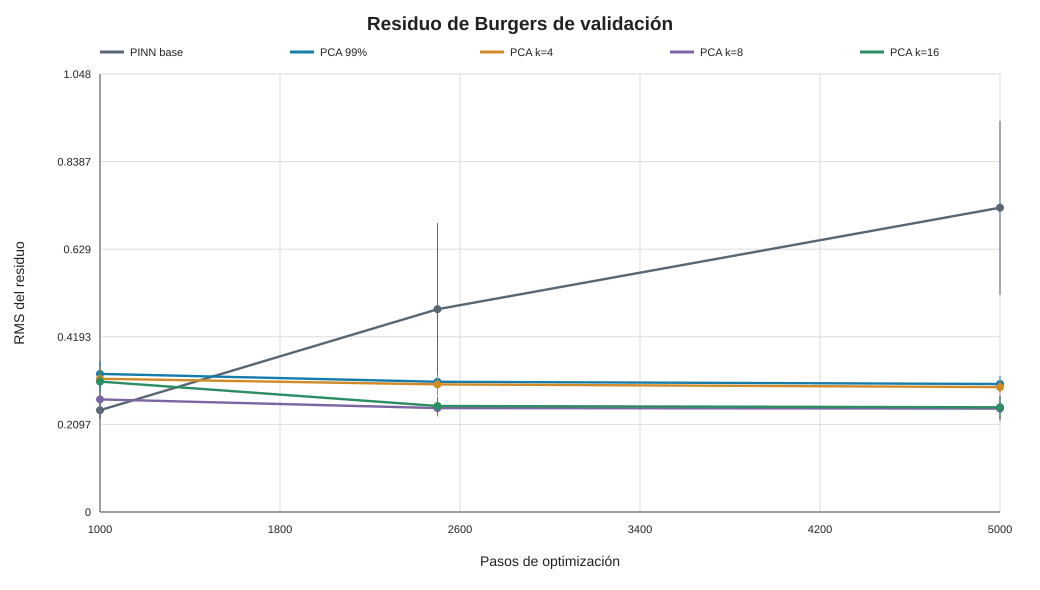

In [7]:
display(SVG(filename=str(RUN_DIR / "validation_residual_vs_steps.svg")))


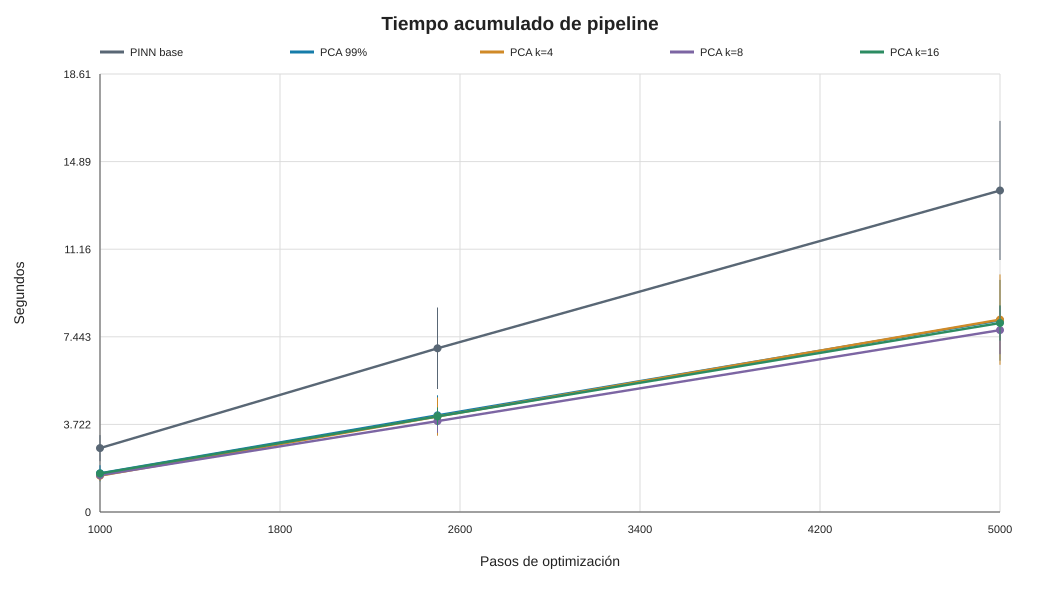

In [8]:
display(SVG(filename=str(RUN_DIR / "pipeline_time_vs_steps.svg")))


## Comparación final


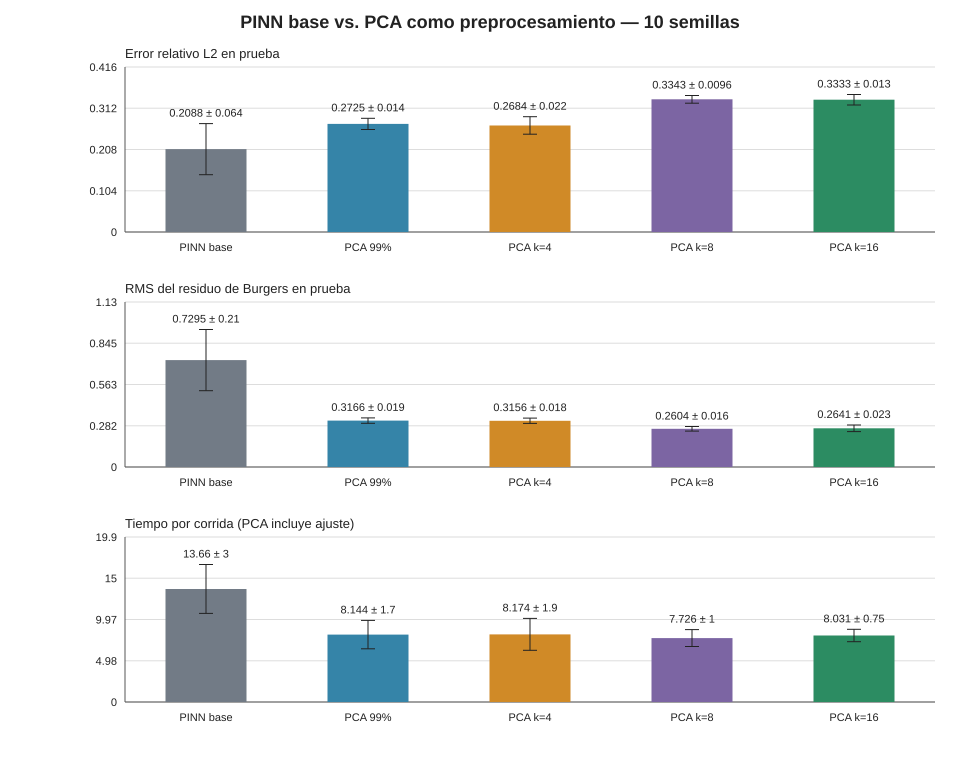

In [9]:
display(SVG(filename=str(RUN_DIR / "final_test_comparison.svg")))


## Lectura preliminar

En la corrida a 1000 pasos, PCA al 99 % tuvo menor error de solución que la PINN base. A 5000 pasos, el orden se invirtió: la PINN base alcanzó menor error relativo `L2`, mientras PCA mantuvo menor tiempo de pipeline. Al aumentar `k` a 8 o 16, el residuo físico de prueba bajó con respecto a `k=3`, aunque aumentó el error de solución. En esta configuración, `k=8` dio el menor residuo promedio entre las variantes PCA, sin ser el mejor en error de solución.

La base, entrenada más tiempo, presentó un residuo de prueba mayor en este experimento. Es un compromiso entre los objetivos medidos y debe investigarse antes de concluir que un `k` es óptimo. Los resultados aplican a esta ecuación, discretización y presupuesto; aún no cubren otros tipos de PDE.


## Reproducir

La configuración está en `configs/burgers_longer_k_sweep.json` y el ejecutor en `scripts/run_longer_k_sweep.py`. Abrir el notebook solo carga los resultados guardados; para regenerarlos, ejecuta el script desde la raíz del repositorio.
